---

# Data Pipeline

---

In [ ]:
# Load in the relevant libraries
import json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import re

In [3]:
# Define the condition
CONDITION = "tb" 

# Define the paths where the json files are located.
JSON_DIR = Path(f"pmc/{CONDITION}/json")

# Define the path of the processed files.
OUTPUT_DIR = Path(f"pmc/{CONDITION}/processed")

# If the path does not exist, then create it.
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

In [4]:
# We can check whether the JSON files exist
json_files = list(JSON_DIR.glob("*.jats.json"))

print("JSON folder:", JSON_DIR.resolve())
print("JSON files found:", len(json_files))


JSON folder: C:\Users\caral\OneDrive\Documents\SCI501\SCI501_Project\pmc\tb\json
JSON files found: 810


In [10]:
# We will create two empty lists to store article details and text passages
articles = []
passages = []

# Go through each downloaded JSON file in the folder
# We will sort the files so they can be processed in order
for file in sorted(json_files):

    # We will open the JSON file using UTF-8 to read special characters
    with open(file, encoding="utf-8") as f:
        data = json.load(f)

    # Get the article metadata and passages from the JATS JSON file
    metadata = data.get("metadata") or {}
    content = data.get("passages") or []

    # Get the PMC ID from the JSON file
    # Remove the .jats.json extension
    pmcid = data.get("pmcid", file.name.replace(".jats.json", ""))

    # Get the publication year from the article citation
    # The year is not stored as a separate field in PMC Cloud metadata
    citation = metadata.get("citation") or ""

    # Find a four-digit publication year in the citation
    year_match = re.search(r"\b(?:19|20)\d{2}\b", citation)

    # Convert the year to a number
    # If the year is missing or invalid, we can store it as NaN
    year = (
        int(year_match.group())
        if year_match else float("nan")
    )

    # We will store one record for each article
    # We keep the main metadata (can be used for later analysis)
    articles.append({
        "pmcid": pmcid,
        "title": metadata.get("title", ""),
        "year": year,
        "doi": metadata.get("doi"),
        "pmid": metadata.get("pmid"),
        "license": metadata.get("license_code")
    })

    # Loop through each passage in the article
    # We will give each passage a number so it can be identified later
    for i, passage in enumerate(content):

        # We extract the text and remove extra spaces at the beginning
        # and end
        text = (passage.get("text") or "").strip()

        # Skip passages that don't contain any text
        if not text:
            continue

        # Get the section information for the current passage
        # JATS stores sections as a list of nested headings
        section_path = passage.get("section") or []

        # Store each passage as a separate record
        # We will keep the PMC ID so the text can be linked to original
        # record
        passages.append({
            "pmcid": pmcid,
            "passage_id": passage.get("passage_id", i),
            "year": year,
            "section": " > ".join(section_path),
            "type": passage.get("type", ""),
            "text": text,
            "word_count": len(text.split())
        })

# Check how many articles and passages were extracted
print("Articles processed:", len(articles))
print("Passages extracted:", len(passages))


Articles processed: 810
Passages extracted: 21142


In [ ]:
print(data["metadata"].keys())
print(data["metadata"])

In [11]:
# Convert the article and passage lists into pandas DataFrames
# so data is easier to organise and analyse
articles_df = pd.DataFrame(articles)
passages_df = pd.DataFrame(passages)

# Check whether any articles or passages were extracted
# Stop the code if either DataFrame is empty
if articles_df.empty or passages_df.empty:
    raise ValueError("No usable JATS articles found.")

# Remove duplicate articles based on their PMC ID
# This ensures each article only appears once in the article dataset
articles_df = articles_df.drop_duplicates(
    subset="pmcid"
)

In [12]:
# Save the article metadata in Parquet format
# Each row contains information about one article
articles_df.to_parquet(
    OUTPUT_DIR / "articles.parquet",
    index=False  # Don't save the DataFrame index
)

# Save the extracted text passages in Parquet format
# Each row contains a passage linked to its original article
passages_df.to_parquet(
    OUTPUT_DIR / "passages.parquet",
    index=False  # Don't save the DataFrame index
)

In [13]:
# Print the total number of articles in the dataset
print("Articles:", len(articles_df))

# Print the total number of text passages extracted from the articles
print("Passages:", len(passages_df))

# Count how many articles have a publication year recorded
# This is important for analysing diagnostic trends over time
print("Publication years available:",
      articles_df["year"].notna().sum())

# Display the first five rows of the article dataset
# This allows me to check the article metadata
display(articles_df.head())

# Display the first five rows of the passage dataset
# This allows me to check how the article text has been organised
display(passages_df.head())


Articles: 810
Passages: 21142
Publication years available: 810


,pmcid,title,year,doi,pmid,license
0,PMC10009416,Risk factors for cannabis use disorders and ca...,2022,10.1002/npr2.12307,36537061.0,CC BY
1,PMC10034075,Case report: Autoimmune glial fibrillary acidi...,2023,10.3389/fneur.2023.1123603,36970528.0,CC BY
2,PMC10038010,Hydrocephalus Caused by Tuberculous Meningitis...,2023,10.2147/IMCRJ.S389204,36968269.0,CC BY-NC
3,PMC10041991,Pharmacokinetics of Antituberculosis Drugs in ...,2023,10.2147/IDR.S401281,36992966.0,CC BY-NC
4,PMC10075254,Diagnosis of extrapulmonary tuberculosis by ul...,2023,10.3389/fcimb.2023.1154939,37033480.0,CC BY


,pmcid,passage_id,year,section,type,text,word_count
0,PMC10009416,1,2022,Abstract,abstract,AbstractAimTo determine the risk factors for c...,208
1,PMC10009416,2,2022,Abstract,abstract,We examined the risk factors of Japanese canna...,103
2,PMC10009416,3,2022,INTRODUCTION,paragraph,Cannabis regulations have undergone significan...,50
3,PMC10009416,4,2022,INTRODUCTION,paragraph,"In the United States (US), the federal governm...",105
4,PMC10009416,5,2022,INTRODUCTION,paragraph,An increasing number of areas have permitted l...,55


In [15]:

# Randomly select an article from the dataset
pmcid = passages_df["pmcid"].dropna().drop_duplicates().sample(
    n=1,
    random_state=123
).iloc[0]

# Get all passages belonging to the selected article
# Sort by passage ID to keep the original article order
article = passages_df[
    passages_df["pmcid"] == pmcid
].sort_values("passage_id")

# Display the article information
print("PMCID:", pmcid)
print("Total passages:", len(article))
print("Total words:", article["word_count"].sum())

# Show all section names available in the selected article
print("\nSections available in this article:")

for section in article["section"].dropna().unique():
    print("-", section)

# Show how many passages and words are in each section
display(
    article.groupby("section")["word_count"]
    .agg(["sum"])
)

# Select the main sections of the article
# Exclude references, tables and figures
main_sections = [
    "title", "abstract", "introduction", "background",
    "methods", "materials", "patients", "results",
    "discussion", "conclusion", "case"
]

# Check whether the section name contains any of the main sections
# This also includes nested sections such as Methods > Diagnostic Criteria
main_article = article[
    article["section"].fillna("").str.lower().apply(
        lambda section: any(
            name in section for name in main_sections
        )
    )
    & (article["type"] != "table")
]

# Combine the passages into one readable document
# Include section names to see where the text comes from
full_text = "\n\n".join(
    f"[{row['section']}]\n{row['text']}"
    for _, row in main_article.iterrows()
)

# Display the first 5000 characters of the article
# This allows me to check whether the text has been extracted correctly
print("\nARTICLE TEXT:\n")
print(full_text[:5000])

# Display a link to the original PMC article for comparison
print(f"\nOriginal article: https://pmc.ncbi.nlm.nih.gov/articles/{pmcid}/")


PMCID: PMC5036109
Total passages: 36
Total words: 5272

Sections available in this article:
- Abstract
- Background
- Materials and Methods
- Materials and Methods > Bacterial strains
- Materials and Methods > Extraction of genomic DNA
- Materials and Methods > Whole genome sequencing > Library preparation and sequencing
- Materials and Methods > Whole genome sequencing > Read quality assessment, assembly and annotation
- Materials and Methods > Genomic analysis
- Materials and Methods > Genomic analysis > Genome rearrangements
- Materials and Methods > Genomic analysis > Identification of polymorphisms
- Materials and Methods > Genomic analysis > Amino acid comparisons
- Results > Genome overview
- Results > Genome rearrangements
- Results > Micro-variants and protein globularity changes
- Results > Proteins reported to be associated with meningitis in M. tuberculosis
- Results > Meningitis-associated genes from other bacterial pathogens
- Discussion
- Conclusion


,sum
section,
Abstract,293
Background,642
Conclusion,95
Discussion,1624
Materials and Methods,19
Materials and Methods > Bacterial strains,157
Materials and Methods > Extraction of genomic DNA,201
Materials and Methods > Genomic analysis,84
Materials and Methods > Genomic analysis > Amino acid comparisons,73



ARTICLE TEXT:

[Abstract]
BackgroundMeningitis is a major cause of mortality in tuberculosis (TB). It is not clear what factors promote central nervous system invasion and pathology but it has been reported that certain strains of Mycobacterium tuberculosis (Mtb) might have genetic traits associated with neurotropism.MethodsIn this study, we generated whole genome sequences of eight clinical strains of Mtb that were isolated from the cerebrospinal fluid (CSF) of patients presenting with tuberculous meningitis (TBM) in Malaysia, and compared them to the genomes of H37Rv and other respiratory Mtb genomes either downloaded from public databases or extracted from local sputum isolates. We aimed to find genomic features that might be distinctly different between CSF-derived and respiratory Mtb.ResultsGenome-wide comparisons revealed rearrangements (translocations, inversions, insertions and deletions) and non-synonymous SNPs in our CSF-derived strains that were not observed in the respirat

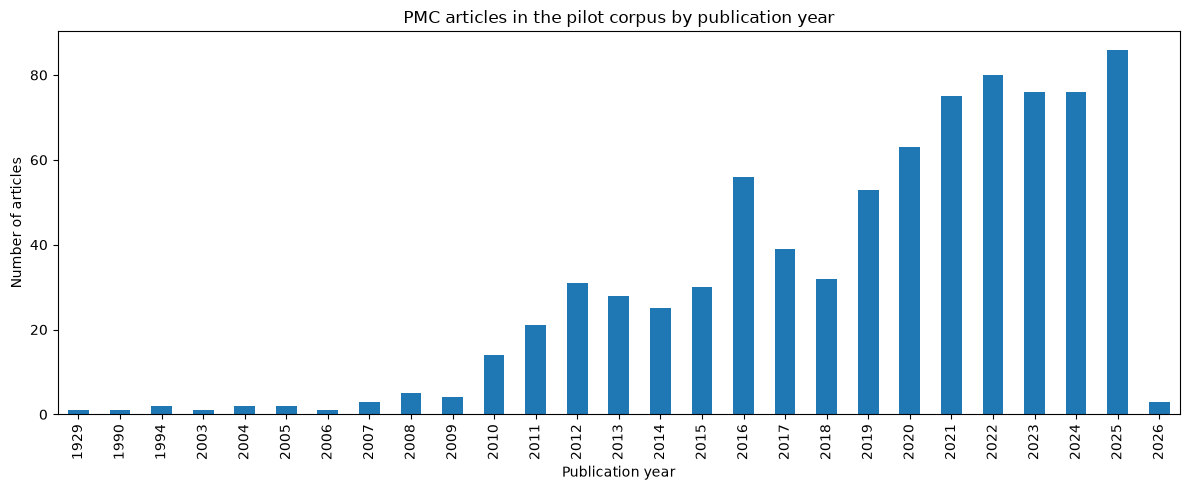

In [16]:
# Count how many unique articles were published each year
year_counts = (

    # Remove articles that don't have a publication year
    articles_df.dropna(subset=["year"])

    # Group the articles by publication year
    .groupby("year")["pmcid"]

    # Count the number of unique PMC articles for each year
    .nunique()

    # Sort the results by year, from oldest to newest
    .sort_index()
)

# Create a bar chart showing the number of articles published each year
year_counts.plot(
    kind="bar",       
    figsize=(12, 5), 
    title="PMC articles in the pilot corpus by publication year"
)

# Add labels to the graph
plt.xlabel("Publication year")
plt.ylabel("Number of articles")

# Adjust the layout so the labels fit properly
plt.tight_layout()

# Display the graph
plt.show()


In [18]:
PATTERN = {
    "Xpert MTB/RIF": r"\b(?:Xpert\s*MTB\s*/\s*RIF|GeneXpert)\b",
    "Xpert Ultra": r"\b(?:Xpert(?:\s+MTB\s*/\s*RIF)?\s+Ultra|MTB\s*/\s*RIF\s+Ultra)\b",
    "TB PCR / NAAT": r"\b(?:polymerase chain reaction|\bPCR\b|\bNAAT\b|nucleic.acid amplification)\b",
    "Mycobacterial culture": r"\b(?:mycobacterial culture|\bMGIT\b|L[oö]wenstein.Jensen|TB culture)\b",
    "AFB / smear": r"\b(?:acid.fast bacill\w*|\bAFB\b|Ziehl.Neelsen|smear microscopy)\b",
    "Biopsy / histology": r"\b(?:biops\w*|histopatholog\w*|granulomatous|caseating granuloma\w*)\b",
    "Adenosine deaminase": r"\b(?:adenosine deaminase|\bADA\b)\b",
    "Cerebrospinal fluid": r"\b(?:cerebrospinal fluid|\bCSF\b)\b",
    "Pleural fluid": r"\b(?:pleural fluid|pleural effusion)\b",
    "Fine-needle aspiration": r"\b(?:fine.needle aspiration|\bFNAC\b|\bFNA\b)\b",
    "Diagnostic accuracy terms": r"\b(?:sensitivit\w*|specificit\w*|diagnostic accurac\w*)\b",
}


In [ ]:
 {
    "Biopsy / histology": r"\b(?:biops\w*|histolog\w*)\b",
    "Endoscopy": r"\bendoscop\w*\b",
    "Autoantibodies": (
        r"\b(?:intrinsic.factor.antibod\w*|"
        r"parietal.cell.antibod\w*|"
        r"anti.parietal.cell)\b"
    ),
    "Vitamin B12": r"\b(?:vitamin B12|cobalamin)\b",
    "Gastrin": r"\bgastrin\b",
    "Pepsinogen": r"\bpepsinogen\w*\b"
}

In [19]:
# Select the main sections of the articles
# JATS stores section names as full headings and may include subsections
main_sections = [
    "abstract", "introduction", "background",
    "methods", "materials", "patients",
    "results", "discussion", "conclusion", "case"
]

# Exclude references, tables, figures and headings
analysis_df = passages_df[
    passages_df["section"].fillna("").str.lower().apply(
        lambda section: any(
            name in section for name in main_sections
        )
    )
    &
    (passages_df["type"] == "paragraph")
].copy()

# Include abstracts, which have a separate passage type in JATS
analysis_df = pd.concat([
    analysis_df,
    passages_df[passages_df["type"] == "abstract"]
]).drop_duplicates(subset=["pmcid", "passage_id"])

# Preliminary diagnostic categories
patterns = PATTERN

for category, pattern in patterns.items():
    analysis_df[category] = analysis_df["text"].str.contains(
        pattern,
        case=False,
        regex=True,
        na=False
    )

# Combine passages into article-level indicators
paper_hits = (
    analysis_df.groupby("pmcid")[list(patterns)]
    .any()
)

trend_df = articles_df[
    ["pmcid", "year"]
].merge(
    paper_hits,
    on="pmcid",
    how="left"
)

for category in patterns:
    trend_df[category] = trend_df[category].fillna(False).astype(bool)

trend_df = trend_df.dropna(subset=["year"])

# Percentage of papers mentioning each category per year
trends = (
    trend_df.groupby("year")[list(patterns)]
    .mean()
    .mul(100)
)

display(trends.round(1))


,Xpert MTB/RIF,Xpert Ultra,TB PCR / NAAT,Mycobacterial culture,AFB / smear,Biopsy / histology,Adenosine deaminase,Cerebrospinal fluid,Pleural fluid,Fine-needle aspiration,Diagnostic accuracy terms
year,,,,,,,,,,,
1929,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1990,0.0,0.0,0.0,0.0,0.0,0.0,0.0,100.0,0.0,0.0,0.0
1994,0.0,0.0,0.0,0.0,0.0,50.0,50.0,50.0,0.0,0.0,0.0
2003,0.0,0.0,100.0,0.0,100.0,100.0,100.0,0.0,100.0,0.0,100.0
2004,0.0,0.0,100.0,0.0,50.0,50.0,50.0,50.0,50.0,0.0,100.0
2005,0.0,0.0,50.0,50.0,100.0,100.0,0.0,0.0,50.0,50.0,0.0
2006,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,100.0
2007,0.0,0.0,66.7,66.7,100.0,66.7,33.3,33.3,0.0,33.3,66.7
2008,0.0,0.0,20.0,0.0,80.0,100.0,20.0,20.0,40.0,40.0,40.0


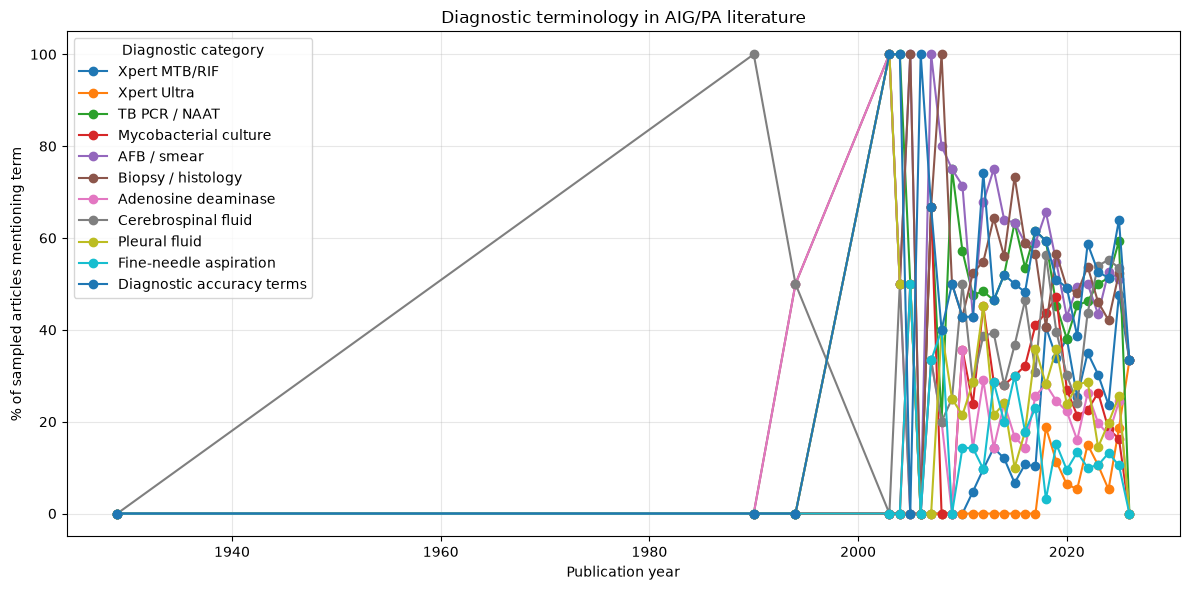

In [20]:
trends.plot(
    figsize=(12, 6),
    marker="o"
)

plt.title("Diagnostic terminology in AIG/PA literature")
plt.xlabel("Publication year")
plt.ylabel("% of sampled articles mentioning term")
plt.legend(title="Diagnostic category")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# Load the processed article metadata
articles_df = pd.read_parquet(
    f"pmc/{CONDITION}/processed/articles.parquet"
)

# Load the processed text passages
passages_df = pd.read_parquet(
    f"pmc/{CONDITION}/processed/passages.parquet"
)